# 7.3 Градиентный спуск и регрессия / 梯度下降与回归
Сначала рассмотрим один параметр, затем обучим прямую по синтетическим данным.
先观察单参数更新，再使用合成数据训练一条直线。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
blue, red = "#356AE6", "#D94F65"
np.set_printoptions(precision=5, suppress=True)

## Скорость обучения / 学习率
$L(w)=(w-3)^2$, $w\leftarrow w-\eta\,2(w-3)$. При $0<\eta<1$ ошибка уменьшается; при $\eta=1$ возникают колебания, при $\eta>1$ — расходимость.
对这个二次函数，学习率在 0 与 1 之间时收敛；等于 1 时振荡；大于 1 时发散。

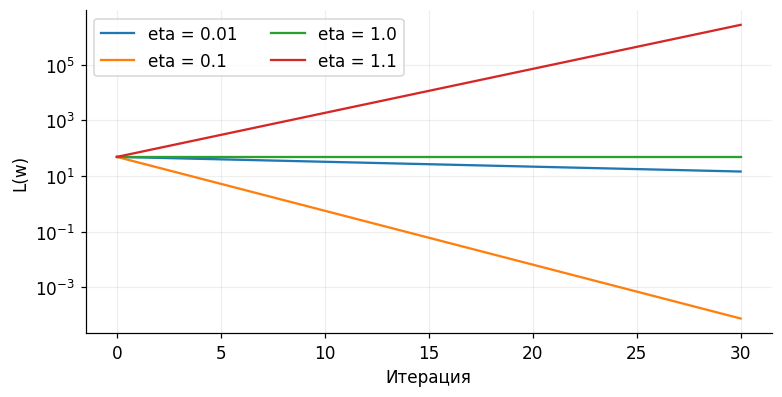

In [2]:
def run_gd(eta, steps=30, w0=-4.0):
    values = [w0]
    for _ in range(steps):
        w = values[-1]
        values.append(w - eta * 2 * (w - 3))
    return np.array(values)

rates = [0.01, 0.1, 1.0, 1.1]
paths = [run_gd(rate) for rate in rates]
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
for rate, path in zip(rates, paths):
    ax.semilogy((path - 3)**2, label=f"eta = {rate}")
ax.set(xlabel="Итерация", ylabel="L(w)")
ax.legend(ncol=2); ax.grid(alpha=0.2)
plt.show()

## Численный градиент / 数值梯度
Для $L(w_1,w_2)=w_1^2+3w_2^2$ аналитический градиент равен $(2w_1,6w_2)$. Сравним его с центральной разностью.
将解析梯度与中心差分结果比较。

In [3]:
def loss_vec(w):
    return w[0]**2 + 3 * w[1]**2

def numeric_gradient(function, w, delta=1e-5):
    result = np.zeros_like(w, dtype=float)
    for i in range(w.size):
        plus, minus = w.copy(), w.copy()
        plus[i] += delta
        minus[i] -= delta
        result[i] = (function(plus) - function(minus)) / (2 * delta)
    return result

point = np.array([1.0, -2.0])
analytic = np.array([2 * point[0], 6 * point[1]])
numeric = numeric_gradient(loss_vec, point)
print("Analytic:", analytic)
print("Numeric: ", numeric)
print("Difference:", np.abs(analytic - numeric))

Analytic: [  2. -12.]
Numeric:  [  2. -12.]
Difference: [0. 0.]


## Данные и разделение / 数据与划分
Генерируем $y=2x-1+\varepsilon$, $\varepsilon\sim N(0,0.3^2)$. Из 160 объектов: 96 train, 32 validation, 32 test.
生成带噪声的线性数据。训练集更新参数，验证集选择学习率，测试集仅在选择结束后评估一次。

In [4]:
rng = np.random.default_rng(42)
x = rng.uniform(-2, 2, 160)
y = 2 * x - 1 + rng.normal(0, 0.3, x.size)
indices = rng.permutation(x.size)
train, valid, test = np.split(indices, [96, 128])
x_train, y_train = x[train], y[train]
x_valid, y_valid = x[valid], y[valid]

def half_mse(prediction, target):
    return 0.5 * np.mean((prediction - target)**2)

## Mini-batch SGD / 小批量随机梯度下降
$L=\frac12\mathrm{MSE}$. После каждой эпохи считаем loss заново по всему train и validation. Последний неполный batch тоже используется.
每轮结束后重新计算整个训练集与验证集的损失，也使用最后一个不完整批次。

In [5]:
def fit_line(x_train, y_train, x_valid, y_valid, lr,
             epochs=80, batch_size=16, seed=7):
    rng = np.random.default_rng(seed)
    w, b = 0.0, 0.0
    history = []
    for epoch in range(epochs):
        order = rng.permutation(x_train.size)
        for start in range(0, x_train.size, batch_size):
            ids = order[start:start + batch_size]
            xb, yb = x_train[ids], y_train[ids]
            error = w * xb + b - yb
            dw = np.mean(error * xb)
            db = np.mean(error)
            w -= lr * dw
            b -= lr * db
        train_loss = half_mse(w * x_train + b, y_train)
        valid_loss = half_mse(w * x_valid + b, y_valid)
        history.append([train_loss, valid_loss])
    return w, b, np.array(history)

learning_rates = [0.001, 0.01, 0.1]
runs = [fit_line(x_train, y_train, x_valid, y_valid, lr)
        for lr in learning_rates]
best = int(np.argmin([run[2][-1, 1] for run in runs]))
w_fit, b_fit, history = runs[best]
for lr, (_, _, curve) in zip(learning_rates, runs):
    print(f"lr={lr:.3f}, validation loss={curve[-1, 1]:.6f}")
print("Selected:", learning_rates[best])
print(f"w={w_fit:.5f}, b={b_fit:.5f}")

lr=0.001, validation loss=1.025499
lr=0.010, validation loss=0.041259
lr=0.100, validation loss=0.041215
Selected: 0.1
w=2.00113, b=-0.99007


Test RMSE: 0.28768


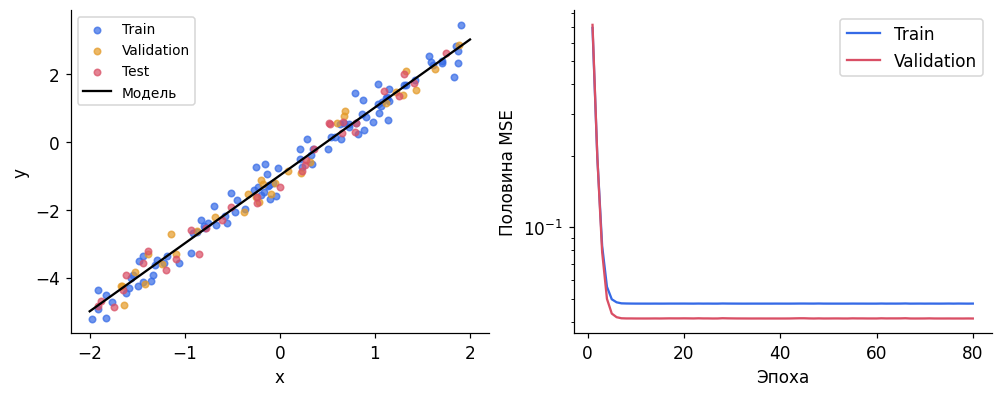

In [6]:
test_prediction = w_fit * x[test] + b_fit
test_rmse = np.sqrt(np.mean((test_prediction - y[test])**2))
print(f"Test RMSE: {test_rmse:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
for ids, label, color in [(train, "Train", blue), (valid, "Validation", "#E49A27"),
                           (test, "Test", red)]:
    axes[0].scatter(x[ids], y[ids], s=18, alpha=0.7, label=label, color=color)
grid = np.linspace(-2, 2, 100)
axes[0].plot(grid, w_fit * grid + b_fit, color="black", label="Модель")
axes[0].set(xlabel="x", ylabel="y"); axes[0].legend(fontsize=9)
axes[1].semilogy(np.arange(1, 81), history[:, 0], label="Train", color=blue)
axes[1].semilogy(np.arange(1, 81), history[:, 1], label="Validation", color=red)
axes[1].set(xlabel="Эпоха", ylabel="Половина MSE"); axes[1].legend()
plt.show()

Для сравнения найдём минимум квадратов на том же train. Test не участвует ни в выборе скорости обучения, ни в подгонке параметров.
用同一训练集的最小二乘解进行对照。测试集不参与学习率选择或参数拟合。

In [7]:
design = np.column_stack([x_train, np.ones_like(x_train)])
w_ls, b_ls = np.linalg.lstsq(design, y_train, rcond=None)[0]
print("Least squares:", w_ls, b_ls)
print("SGD minus least squares:", w_fit - w_ls, b_fit - b_ls)

Least squares: 2.007329433791947 -0.9894322010406442
SGD minus least squares: -0.006201463757339987 -0.000642413416365839
